In [1]:
!pip install yfinance --upgrade


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import yfinance as yf
import pandas as pd
data=yf.download("AAPL",start="2015-01-01",end="2023-01-01")

[*********************100%***********************]  1 of 1 completed


In [3]:
print(data.head())
print()
print(data.tail())


Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2015-01-02  24.153408  24.619554  23.715982  24.608507  212818400
2015-01-05  23.472967  24.003180  23.287393  23.923648  257142000
2015-01-06  23.475176  23.733654  23.115072  23.537034  263188400
2015-01-07  23.804346  23.903760  23.572377  23.682838  160423600
2015-01-08  24.718969  24.776410  24.014227  24.131318  237458000

Price            Close        High         Low        Open    Volume
Ticker            AAPL        AAPL        AAPL        AAPL      AAPL
Date                                                                
2022-12-23  129.449310  129.999070  127.269896  128.526493  63814900
2022-12-27  127.652748  129.007523  126.366700  128.978073  69007800
2022-12-28  123.735718  128.634488  123.568828  127.299351  85438400
2022-12-29  127.240448  128.094538  125.394821  125.65006

In [4]:
from sklearn.preprocessing import MinMaxScaler
scale=MinMaxScaler()
scaled_values=scale.fit_transform(data["Close"])
print(scaled_values)

[[0.02304535]
 [0.01871461]
 [0.01872867]
 ...
 [0.65684766]
 [0.6791539 ]
 [0.68115328]]


In [5]:
import numpy as np
sequ_len=60
X=[]
y=[]
for i in range(len(scaled_values)-sequ_len):
    X.append(scaled_values[i:i+sequ_len])
    y.append(scaled_values[i+sequ_len])

X=np.array(X)
y=np.array(y)

print(X[0])
print(y[0])

[[0.02304535]
 [0.01871461]
 [0.01872867]
 [0.0208237 ]
 [0.02664492]
 [0.02681363]
 [0.02293281]
 [0.02429673]
 [0.02370619]
 [0.01951607]
 [0.01834901]
 [0.0221876 ]
 [0.02335465]
 [0.02736197]
 [0.02817754]
 [0.02834625]
 [0.02277817]
 [0.03145368]
 [0.0365015 ]
 [0.03405495]
 [0.0361219 ]
 [0.03615004]
 [0.03742952]
 [0.03862945]
 [0.03720372]
 [0.03831887]
 [0.0415656 ]
 [0.04560287]
 [0.04783324]
 [0.04870845]
 [0.04976723]
 [0.05102353]
 [0.05064239]
 [0.05212461]
 [0.05706534]
 [0.05589374]
 [0.05112235]
 [0.05342328]
 [0.05065652]
 [0.05154585]
 [0.05192699]
 [0.05076946]
 [0.04776268]
 [0.04803088]
 [0.04879318]
 [0.0450806 ]
 [0.04187618]
 [0.04499588]
 [0.04378188]
 [0.04570168]
 [0.048652  ]
 [0.05067067]
 [0.04930136]
 [0.04704269]
 [0.04889198]
 [0.04815796]
 [0.04348544]
 [0.04469943]
 [0.04330195]
 [0.04770622]]
[0.04496764]


In [6]:
print(X.shape)

(1954, 60, 1)


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense,Dropout

In [9]:
model=Sequential()
model.add(LSTM(units=50,return_sequences=True,input_shape=X.shape[1:]))
model.add(Dropout(0.2))
model.add(LSTM(units=50,return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(1))
model.compile(optimizer="Adam",loss="mean_squared_error",metrics=["Accuracy"])

c:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
train_size=int(0.8*len(X))
x_train=X[:train_size]
x_test=X[train_size:]

y_train=y[:train_size]
y_test=y[train_size:]

In [11]:
model.fit(x_train,y_train,epochs=50,batch_size=16,validation_data=(x_test,y_test))



Epoch 1/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - Accuracy: 6.3980e-04 - loss: 0.0057 - val_Accuracy: 0.0026 - val_loss: 0.0017
Epoch 2/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - Accuracy: 6.3980e-04 - loss: 0.0012 - val_Accuracy: 0.0026 - val_loss: 0.0019
Epoch 3/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - Accuracy: 6.3980e-04 - loss: 0.0010 - val_Accuracy: 0.0026 - val_loss: 0.0021
Epoch 4/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - Accuracy: 6.3980e-04 - loss: 0.0011 - val_Accuracy: 0.0026 - val_loss: 0.0019
Epoch 5/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - Accuracy: 6.3980e-04 - loss: 9.1333e-04 - val_Accuracy: 0.0026 - val_loss: 0.0014
Epoch 6/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - Accuracy: 6.3980e-04 - loss: 9.3095e-04 - val_Accuracy: 0.0026 - val_loss: 0.0019
Epoch 7/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - Accuracy: 6.3980e-04 - loss: 7.9730e-04 - val_Accuracy: 0.0026 - val_loss: 0.0025
Epoch 8/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - Accuracy: 6.3980e-

In [12]:
predictions=model.predict(x_test)
new_predictions=scale.inverse_transform(predictions)
new_y=scale.inverse_transform(y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step


In [13]:
from sklearn.metrics import mean_absolute_error
errors=mean_absolute_error(new_y,new_predictions)
print(errors)

3.106037949662075


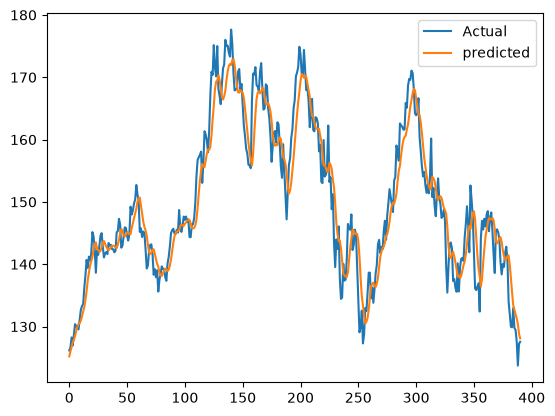

In [15]:
import matplotlib.pyplot as plt
plt.plot(new_y,label="Actual")
plt.plot(new_predictions,label="predicted")
plt.legend()
plt.show()